In [1]:
import kagglehub

path = kagglehub.dataset_download("unclesamulus/blood-cells-image-dataset")
print("Ruta:", path)

c:\Users\Julen\Desktop\Proyecto Detector Cáncer\leukemia-cell-classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 268M/268M [00:11<00:00, 25.0MB/s] 

Extracting files...


Ruta: C:\Users\Julen\.cache\kagglehub\datasets\unclesamulus\blood-cells-image-dataset\versions\2


In [2]:
from pathlib import Path

root = Path(path)
for p in sorted(root.rglob("*")):
    if p.is_dir():
        n = sum(1 for f in p.iterdir() if f.is_file())
        print(p.relative_to(root), "->", n, "archivos")

bloodcells_dataset -> 0 archivos
bloodcells_dataset\basophil -> 1218 archivos
bloodcells_dataset\eosinophil -> 3117 archivos
bloodcells_dataset\erythroblast -> 1551 archivos
bloodcells_dataset\ig -> 2895 archivos
bloodcells_dataset\lymphocyte -> 1214 archivos
bloodcells_dataset\monocyte -> 1420 archivos
bloodcells_dataset\neutrophil -> 3329 archivos
bloodcells_dataset\platelet -> 2348 archivos


{'basophil': 1218, 'eosinophil': 3117, 'erythroblast': 1551, 'ig': 2895, 'lymphocyte': 1214, 'monocyte': 1420, 'neutrophil': 3329, 'platelet': 2348} | total: 17092


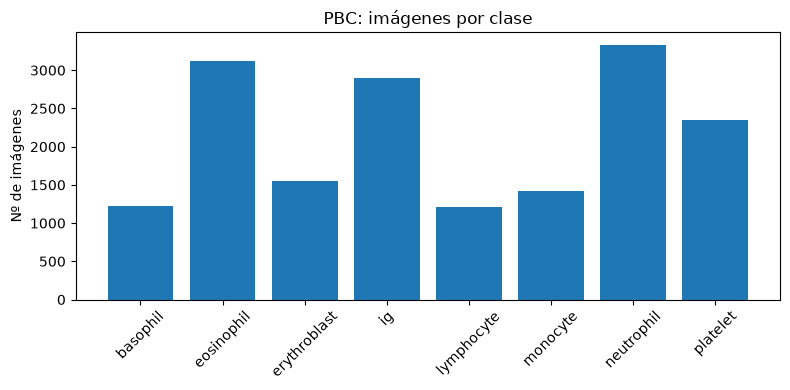

In [3]:
import matplotlib.pyplot as plt

data_dir = Path(path) / "bloodcells_dataset"

counts = {d.name: len(list(d.glob("*"))) for d in sorted(data_dir.iterdir()) if d.is_dir()}
print(counts, "| total:", sum(counts.values()))

plt.figure(figsize=(8, 4))
plt.bar(counts.keys(), counts.values())
plt.xticks(rotation=45)
plt.ylabel("Nº de imágenes")
plt.title("PBC: imágenes por clase")
plt.tight_layout()
plt.show()

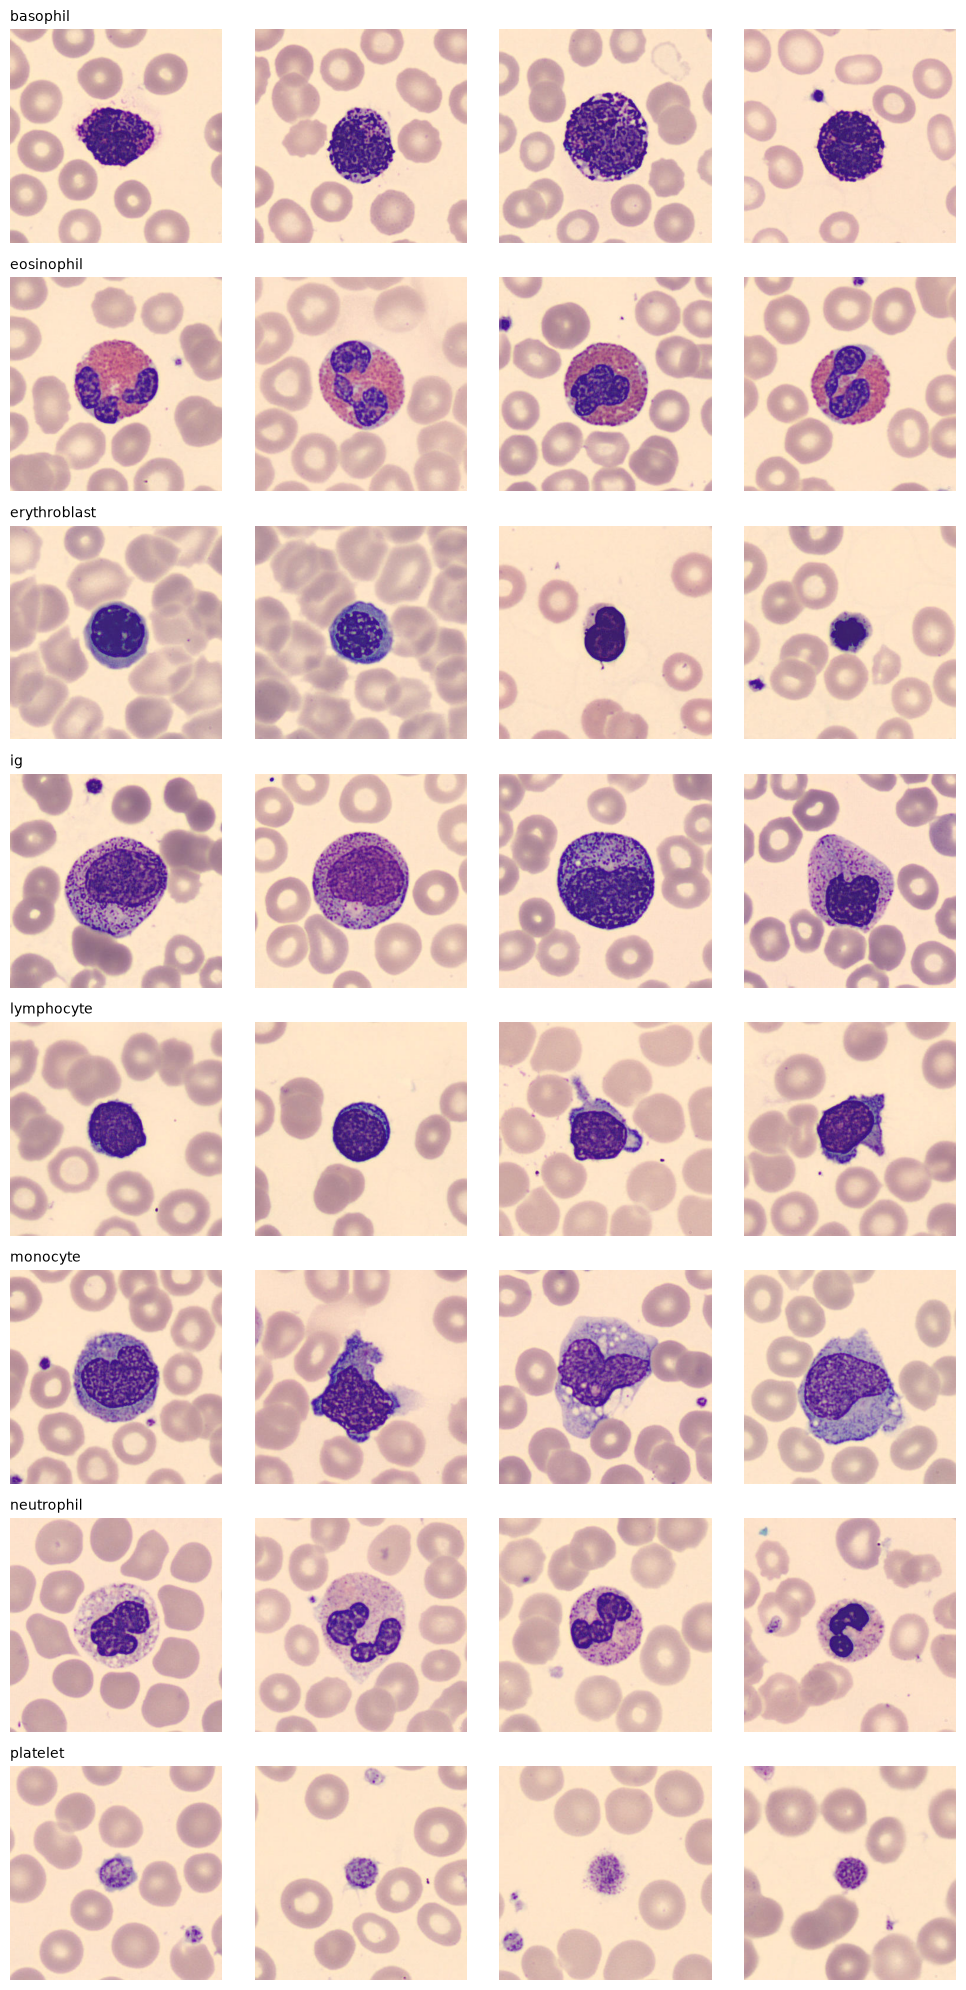

Tamaño de una imagen: (360, 363)


In [4]:
import random
from PIL import Image

classes = sorted(counts.keys())
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.5 * len(classes)))

for i, c in enumerate(classes):
    files = random.sample(list((data_dir / c).glob("*")), 4)
    for j, f in enumerate(files):
        axes[i, j].imshow(Image.open(f))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c, loc="left", fontsize=10)

plt.tight_layout()
plt.show()

print("Tamaño de una imagen:", Image.open(files[0]).size)